
training [STANDARD] tinyml model
c++ class mapping:
  0 -> FALL_IMPACT
  1 -> HEAT_STRAIN
  2 -> NOMINAL
  3 -> PHYSICAL_EXERTION
  4 -> RESPIRATORY_DISTRESS
[STANDARD] test acc: 99.57% | loss: 0.0147
Saved artifact at '/tmp/tmpk5dxtmsl'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 8), dtype=tf.float32, name='keras_tensor_60')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  140055263017296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140055263007312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140055263006736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140055263017680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140055263010000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140055263010192: TensorSpec(shape=(), dtype=tf.resource, name=None)

training [ELDERLY] tinyml model
[ELDERLY] test acc: 99.53% | loss: 0.0168
Saved artifact at '/tmp/tm

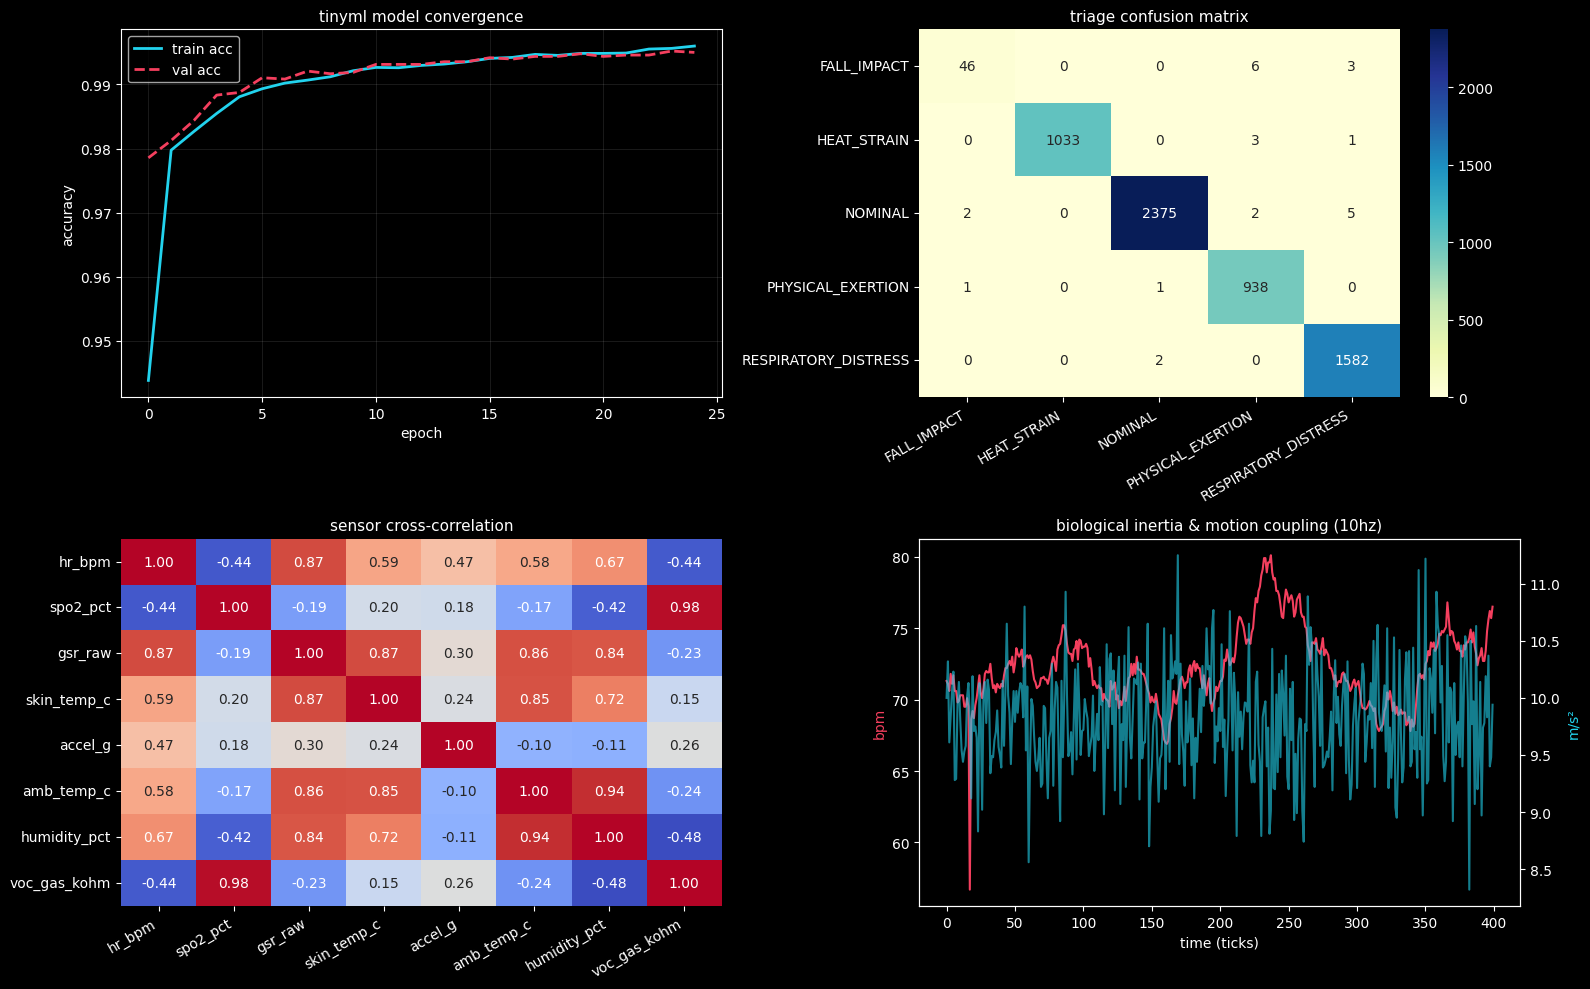

done. header and evaluation png are ready.


In [8]:
import os
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report

# for our plots
plt.style.use('dark_background')

profiles = ["standard", "elderly", "industrial"]

# dumping all three models into a single c++ header.
# the esp32 nvs memory will determine which pointer to load at runtime.
c_header = """// qyra v2 multi-demographic tinyml models
// compiled for esp32-s3. includes standard, elderly, and industrial profiles.

#ifndef QYRA_MULTI_MODEL_H
#define QYRA_MULTI_MODEL_H

"""

# tracking the standard profile run for the visual evaluation graphs
std_history = None
std_X_test, std_y_test, std_y_pred = None, None, None
std_classes = None
std_df = None

for profile in profiles:
    csv_name = f"qyra_data_{profile}.csv"
    if not os.path.exists(csv_name):
        print(f"error: upload {csv_name} to colab first.")
        exit()

    print(f"\ntraining [{profile.upper()}] tinyml model")
    df = pd.read_csv(csv_name)

    X = df.drop('label', axis=1).values
    y_text = df['label'].values

    # map string labels to ints: 0=FALL, 1=HEAT, 2=NOMINAL, 3=EXERTION, 4=RESP_ERR
    encoder = LabelEncoder()
    y = encoder.fit_transform(y_text)

    if profile == "standard":
        print("c++ class mapping:")
        for idx, cls in enumerate(encoder.classes_):
            print(f"  {idx} -> {cls}")

    # scale features so the gsr adc range (0-4095) doesn't overpower the accel range (~9.8)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

    # keep dense layers shallow (24->12->5) so esp32 s3 inference takes <3ms
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_train.shape[1],)),
        tf.keras.layers.Dense(24, activation='relu'),
        tf.keras.layers.Dense(12, activation='relu'),
        tf.keras.layers.Dense(len(encoder.classes_), activation='softmax')
    ])

    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    # 25 epochs is usually enough to hit ~99% on the synthetic data
    history = model.fit(X_train, y_train, epochs=25, batch_size=64, validation_split=0.2, verbose=0)
    loss, acc = model.evaluate(X_test, y_test, verbose=0)
    print(f"[{profile.upper()}] test acc: {acc * 100:.2f}% | loss: {loss:.4f}")

    if profile == "standard":
        std_history = history
        std_X_test, std_y_test = X_test, y_test
        std_y_pred = np.argmax(model.predict(X_test, verbose=0), axis=-1)
        std_classes = encoder.classes_
        std_df = df

    # 8-bit dynamic range quantization shrinks the model footprint for esp32 s3 flash memory
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_bytes = converter.convert()

    # extract scaler math for live c++ inference
    hex_vals = ', '.join([f'0x{b:02x}' for b in tflite_bytes])
    means_str = ", ".join([f"{val:.4f}f" for val in scaler.mean_])
    stds_str = ", ".join([f"{val:.4f}f" for val in scaler.scale_])

    p_upper = profile.upper()
    c_header += f"// {profile} demographic profile ({len(tflite_bytes)} bytes)\n"
    c_header += f"const float MEANS_{p_upper}[8] = {{{means_str}}};\n"
    c_header += f"const float STDDEVS_{p_upper}[8] = {{{stds_str}}};\n"
    c_header += f"alignas(8) const unsigned char qyra_model_{profile}[] = {{\n"

    # chunk hex array so the compiler doesn't choke on a single long line
    for i in range(0, len(hex_vals), 108):
        c_header += "  " + hex_vals[i:i+108] + "\n"

    c_header += f"}};\nconst unsigned int qyra_model_{profile}_len = {len(tflite_bytes)};\n\n"

c_header += "#endif // QYRA_MULTI_MODEL_H\n"

# writing directly to file instead of using xxd as colab was giving 0-byte issues during training
with open("qyra_multi_model.h", "w") as f:
    f.write(c_header)

print(f"\ngenerated 'qyra_multi_model.h' ({os.path.getsize('qyra_multi_model.h')} bytes).")


# rendering evaluation plots
print("rendering evaluation graphics...")
fig = plt.figure(figsize=(16, 10))

# 1. training convergence
ax1 = plt.subplot(2, 2, 1)
ax1.plot(std_history.history['accuracy'], color='#22d3ee', linewidth=2, label='train acc')
ax1.plot(std_history.history['val_accuracy'], color='#f43f5e', linewidth=2, linestyle='--', label='val acc')
ax1.set_title('tinyml model convergence', fontsize=11)
ax1.set_xlabel('epoch')
ax1.set_ylabel('accuracy')
ax1.legend()
ax1.grid(alpha=0.1)

# 2. confusion matrix
ax2 = plt.subplot(2, 2, 2)
cm = confusion_matrix(std_y_test, std_y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu', xticklabels=std_classes, yticklabels=std_classes, ax=ax2)
ax2.set_title('triage confusion matrix', fontsize=11)
plt.setp(ax2.get_xticklabels(), rotation=30, ha='right')

# 3. sensor cross-correlation
ax3 = plt.subplot(2, 2, 3)
corr = std_df.drop('label', axis=1).corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=ax3, cbar=False)
ax3.set_title('sensor cross-correlation', fontsize=11)
plt.setp(ax3.get_xticklabels(), rotation=30, ha='right')

# 4. biological inertia & sensor coupling
ax4 = plt.subplot(2, 2, 4)
if os.path.exists("qyra_sequential_preview.csv"):
    seq_df = pd.read_csv("qyra_sequential_preview.csv")
    ax4.plot(seq_df.index[:400], seq_df['hr_bpm'][:400], color='#f43f5e', label='heart rate')
    ax4_twin = ax4.twinx()
    ax4_twin.plot(seq_df.index[:400], seq_df['accel_g'][:400], color='#22d3ee', alpha=0.6, label='accel (m/s²)')
    ax4.set_title('biological inertia & motion coupling (10hz)', fontsize=11)
    ax4.set_xlabel('time (ticks)')
    ax4.set_ylabel('bpm', color='#f43f5e')
    ax4_twin.set_ylabel('m/s²', color='#22d3ee')
else:
    sns.kdeplot(data=std_df, x='hr_bpm', hue='label', fill=True, ax=ax4)
    ax4.set_title('heart rate distribution', fontsize=11)

plt.tight_layout()
plt.savefig('qyra_ml_evaluation.png', dpi=120)
plt.show()

print("done. header and evaluation png are ready.")